In [1]:
#step 1:Import all necessary libraries

import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.datasets import mnist 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

TypeError: Descriptors cannot be created directly.
If this call came from a _pb2.py file, your generated code is out of date and must be regenerated with protoc >= 3.19.0.
If you cannot immediately regenerate your protos, some other possible workarounds are:
 1. Downgrade the protobuf package to 3.20.x or lower.
 2. Set PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION=python (but this will use pure-Python parsing and will be much slower).

More information: https://developers.google.com/protocol-buffers/docs/news/2022-05-06#python-updates

In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 [==============================] - 3s 0us/step


In [6]:
print("Training data shape:", X_train.shape)
print("Trainig labels shape:", y_train.shape)
print("Test data shape:", X_test.shape)
print("Test labels shape:",y_test.shape)

Training data shape: (60000, 28, 28)
Trainig labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


In [7]:
X_train =X_train/255.0
X_test = X_test/255.0

In [8]:
y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

In [ ]:
#step 5:
model = Sequential([
    #flatten the layer converts 28*28 image to 784-dimensional vector
    Flatten(input_shape=(28, 28)),
    #dense(fully connected) layer with 128 neurons and ReLU activation
    Dense(128, activation='relu'),
    #output layer with 10 neurons (one for each digit) and softmax activation
    #softmax converts the output to a probability (sum to 1)
    Dense(10, activation='softmax')
    
])

In [ ]:
# Step 6:compile the model
#specify the optimizer, loss function, and metrics to track 
model.compile(optimizer='adam',  #popular optimizer that adapts learning rate
              loss='categorical_crossentropy',  #standard loss for multi-class 
                metrics=['accuracy'])    #track accuracy during training

In [12]:
#step 7:train the model
#train for 10 epochs (passes through the entire dataset)
#use 20% of training data for validation
history = model.fit(
    X_train, y_train, 
    epochs=50, 
    validation_split=0.2,
    verbose=1,  #show training progress
)

Epoch 1/50
1500/1500 [==============================] - 6s 3ms/step - loss: 0.2849 - accuracy: 0.9193 - val_loss: 0.1693 - val_accuracy: 0.9516
Epoch 2/50
1500/1500 [==============================] - 5s 3ms/step - loss: 0.1269 - accuracy: 0.9621 - val_loss: 0.1084 - val_accuracy: 0.9675
Epoch 3/50
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0866 - accuracy: 0.9744 - val_loss: 0.1040 - val_accuracy: 0.9681
Epoch 4/50
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0637 - accuracy: 0.9812 - val_loss: 0.0891 - val_accuracy: 0.9728
Epoch 5/50
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0478 - accuracy: 0.9853 - val_loss: 0.1084 - val_accuracy: 0.9675
Epoch 6/50
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0394 - accuracy: 0.9880 - val_loss: 0.0885 - val_accuracy: 0.9735
Epoch 7/50
1500/1500 [==============================] - 5s 4ms/step - loss: 0.0305 - accuracy: 0.9912 - val_loss: 0.0815 - val_accuracy:

In [14]:
#Step 8: evaluate the model performance on test data
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'\nTest accuracy  : {test_acc:.4f}')#should be around 97.98%


313/313 [==============================] - 1s 2ms/step - loss: 0.1521 - accuracy: 0.9795

Test accuracy  : 0.9795


In [17]:
#step 9: make predictions on test image
sample_index = 42  #you can change this to any index (0-9999)
sample_image = X_test[sample_index]
sample_label =np.argmax(y_test[sample_index])   #convert one-hot encoded label back to digital

#Model expects batch of images  ,so we need to add dimension with reshape

prediction= model.predict(sample_image.reshape(1, 28, 28))  #reshape to (1, 28, 28)
predicted_label=np.argmax(prediction)  #get the digital with highest probability

1/1 [==============================] - 0s 31ms/step


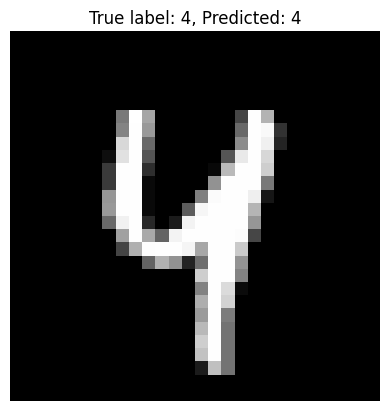

In [18]:
#step 10:display the results
plt.imshow(sample_image, cmap='gray')
plt.title(f'True label: {sample_label}, Predicted: {predicted_label}')
plt.axis('off')  #hide axes
plt.show()